In [1]:
import sys, os
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

# Normal versus Student-t estimation and goodness-of-fit

In [2]:
from src.distribution_fitting import step7, step8
display(step7())

,Bank,Normal MM mu,Normal MM sigma,Student-t MM mu,Student-t MM scale,Student-t MM nu,Student-t MLE mu,Student-t MLE scale,Student-t MLE nu
0,DBS,0.000556,0.011471,0.000556,0.008967,5.142871,0.000411,0.008308,4.141789
1,OCBC,0.000361,0.010215,0.000361,0.008012,5.196639,0.000396,0.007461,4.249814
2,UOB,0.000370,0.010895,0.000370,0.008519,5.146416,0.000300,0.007671,3.818417


Method of Moments relies on noisy sample fourth moments and gives nu≈5.1, while MLE gives nu≈4.1; fourth moments barely exist theoretically near nu=4. The corrected MM scale uses sqrt((nu-2)/nu).

In [3]:
tests = step8()
display(tests)

,Bank,LRT_Lambda,LRT_parametric_bootstrap_p,Normal KS D,Normal KS bootstrap p,Student-t KS D,Student-t KS bootstrap p
0,DBS,381.055866,0.000999,0.061418,0.000999,0.014011,0.065934
1,OCBC,371.221985,0.000999,0.052021,0.000999,0.028998,0.000999
2,UOB,413.655124,0.000999,0.059720,0.000999,0.018984,0.000999


Parametric LRT evidence rejects Normality with p<0.001. Student-t KS is not rejected for DBS (p≈0.066), but is rejected for OCBC and UOB at the 5% level.

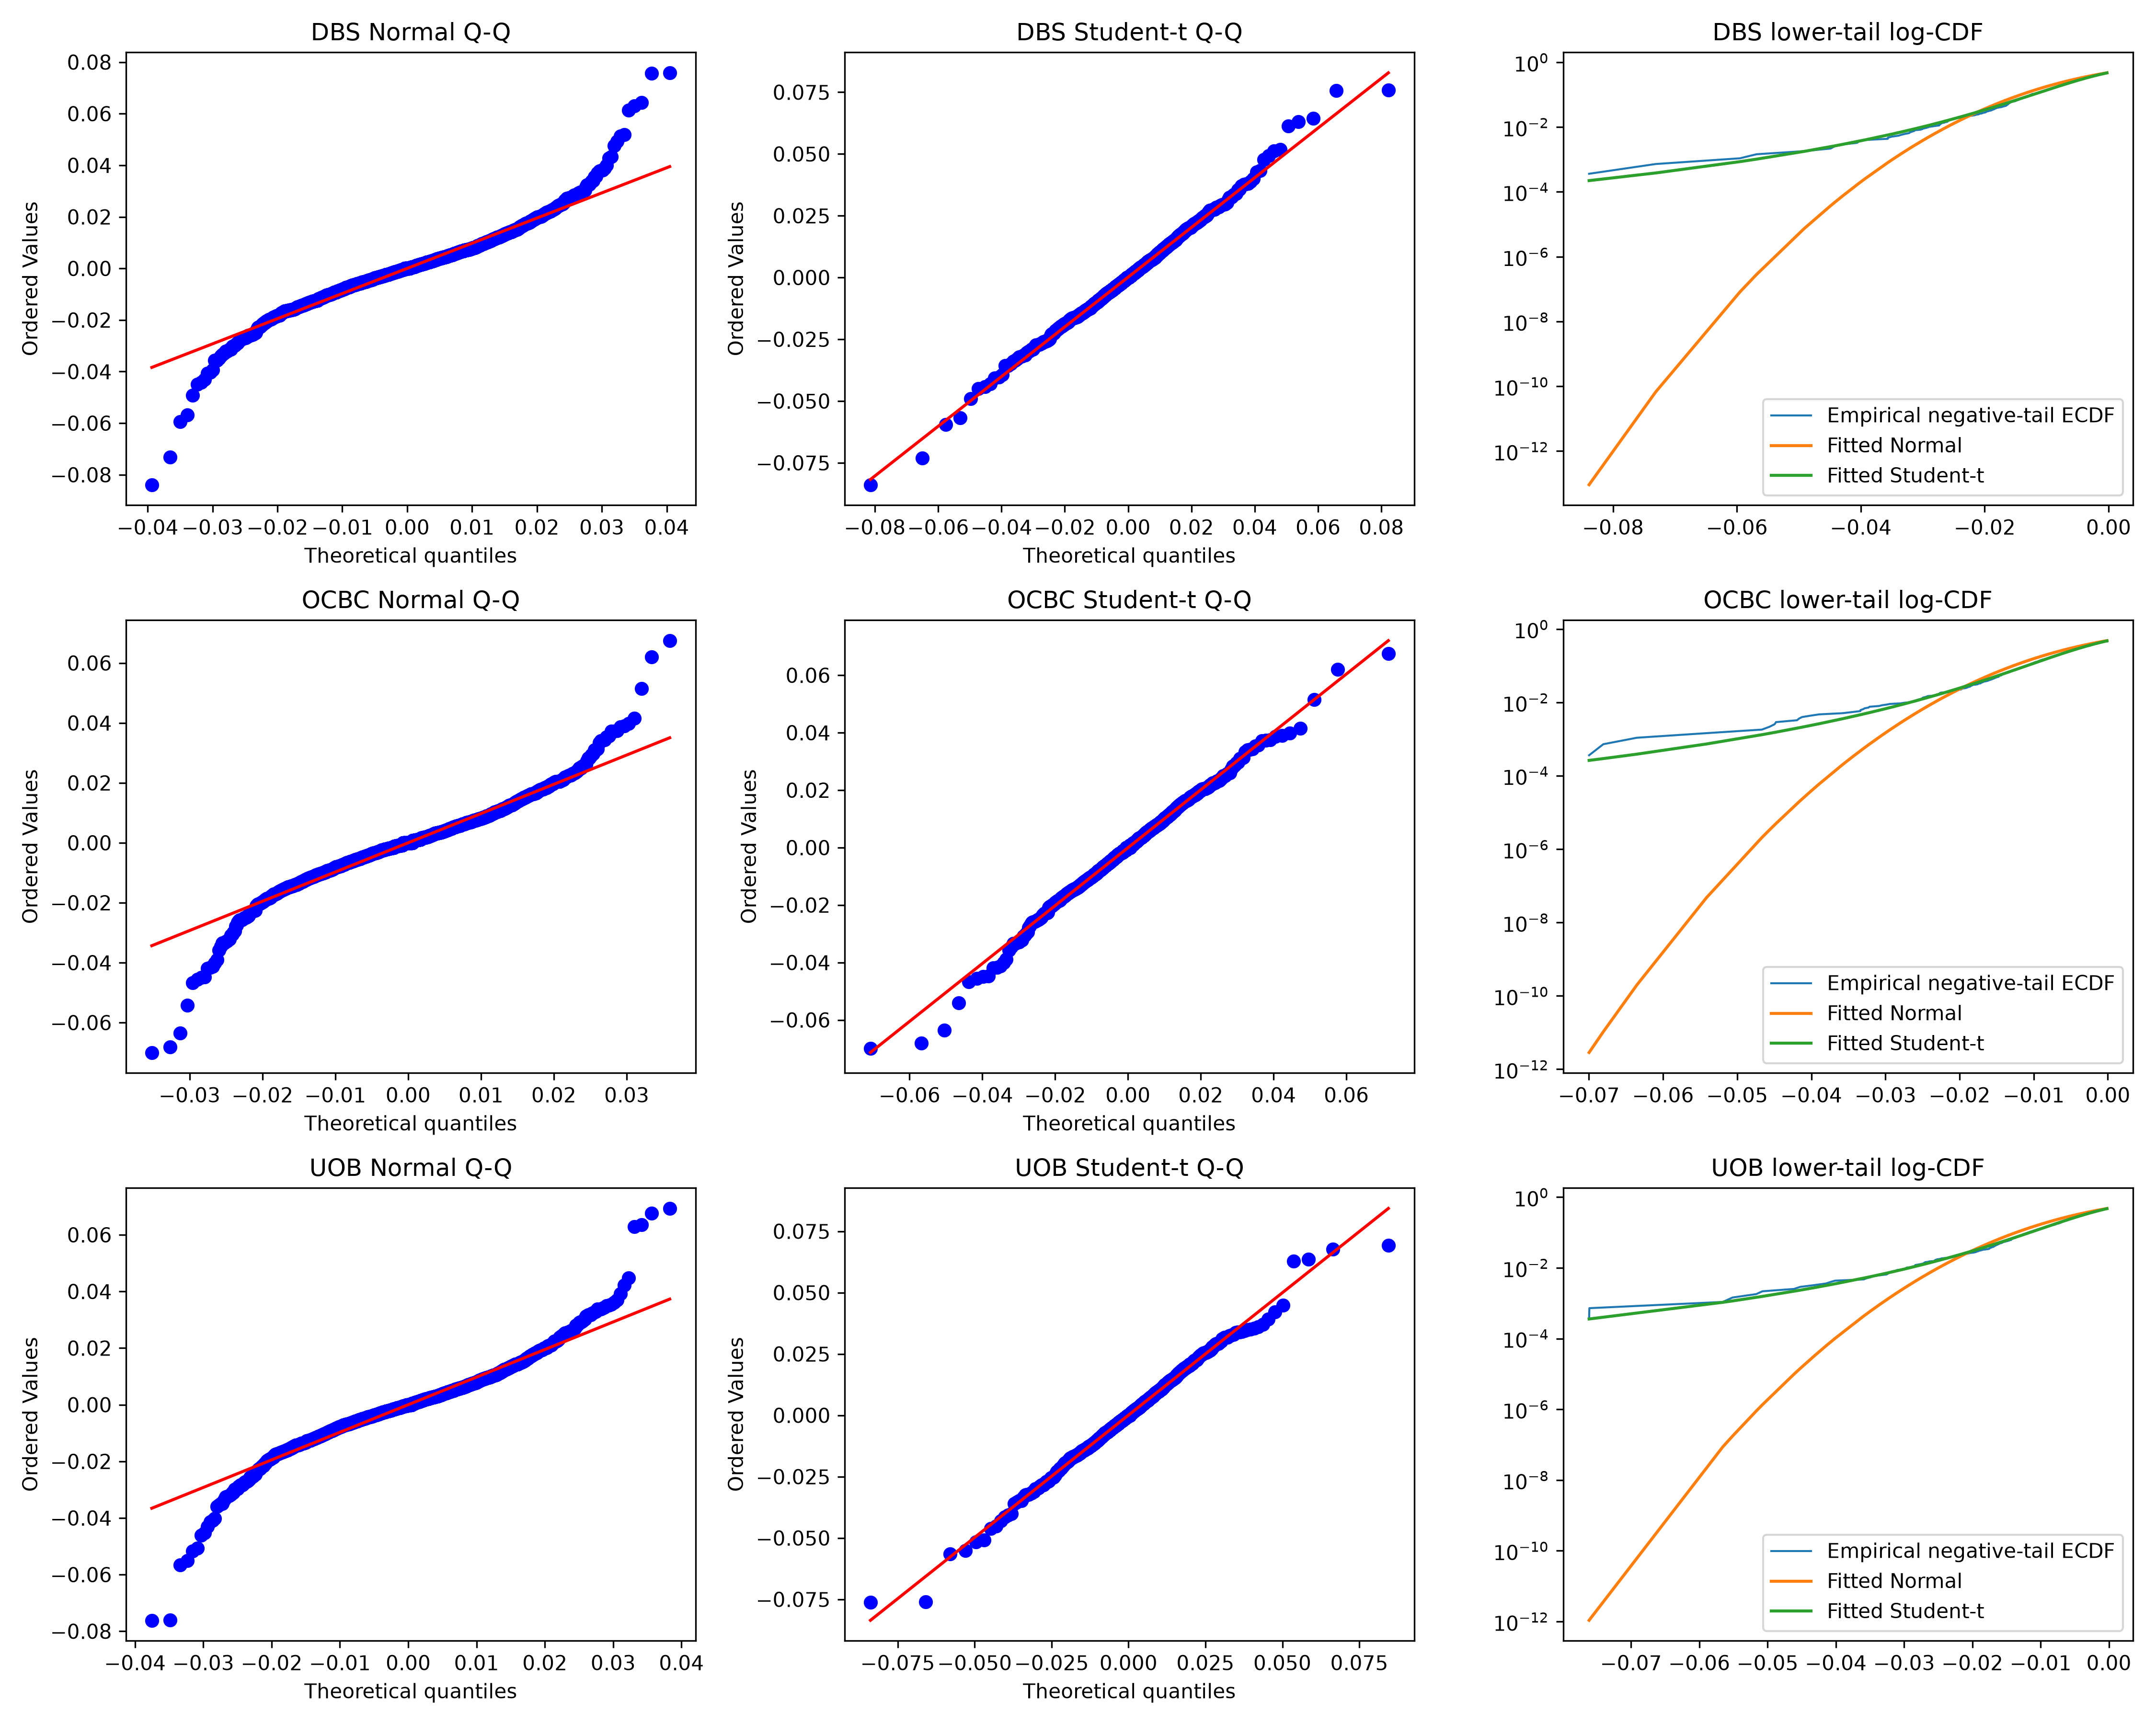

In [4]:
from IPython.display import Image, display
display(Image(filename="outputs/figures/step8_normal_vs_t_qq_ecdf.png"))

Q-Q plots show tail improvement from Student-t, while the lower-tail log-CDF panel reveals that Normal fits materially understate left-tail probabilities.